In [ ]:
#Business Objective

'''Define the objective of prediction.'''

#Constraints
'''High prediction accuracy
Low false classifications
Interpretable model
Faster prediction for business decisions'''

In [ ]:
# Basic Libraries
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

# Models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve

# Tree Visualization
from sklearn import tree

In [ ]:
df = pd.read_csv('/content/Company_Data.csv')
df.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [ ]:
#data understanding
df.shape
df.info()
df.describe()
df.isnull().sum()
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Sales        400 non-null    float64
 1   CompPrice    400 non-null    int64  
 2   Income       400 non-null    int64  
 3   Advertising  400 non-null    int64  
 4   Population   400 non-null    int64  
 5   Price        400 non-null    int64  
 6   ShelveLoc    400 non-null    object 
 7   Age          400 non-null    int64  
 8   Education    400 non-null    int64  
 9   Urban        400 non-null    object 
 10  US           400 non-null    object 
dtypes: float64(1), int64(7), object(3)
memory usage: 34.5+ KB


np.int64(0)

In [ ]:
#data dictionary
'''Feature	  Data Type	 Description	    Relevance
   Sales	    Float	     Product Sales	  Target
   CompPrice	Integer	   Competitor Price	Important
   Income	    Integer	   Customer Income	Important'''

In [ ]:
#1MBD
df.mean(numeric_only=True)

#2MBD
df.var(numeric_only=True)

#3MBD
df.skew(numeric_only=True)

#4MBD
df.kurt(numeric_only=True)

,0
Sales,-0.080877
CompPrice,0.041666
Income,-1.085289
Advertising,-0.545118
Population,-1.202318
Price,0.451885
Age,-1.134392
Education,-1.298332


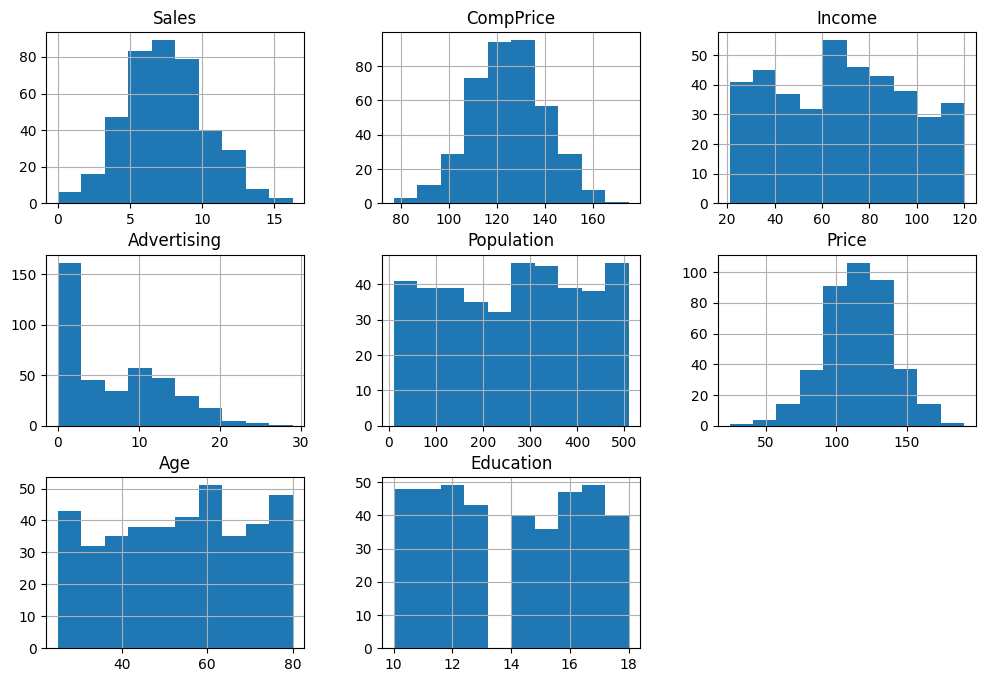

In [ ]:
#EDA
df.hist(figsize=(12,8))
plt.show()

<Axes: ylabel='Sales'>

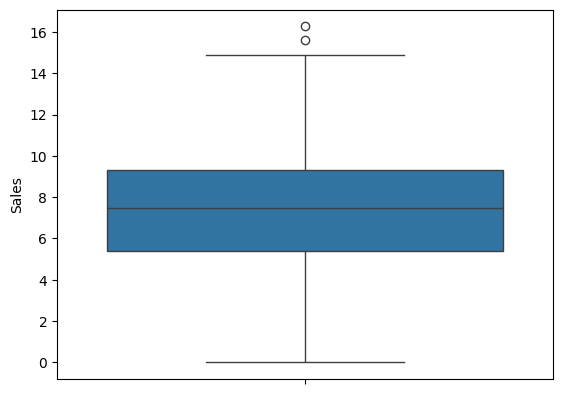

In [ ]:
sns.boxplot(df['Sales'])

<Axes: xlabel='ShelveLoc', ylabel='count'>

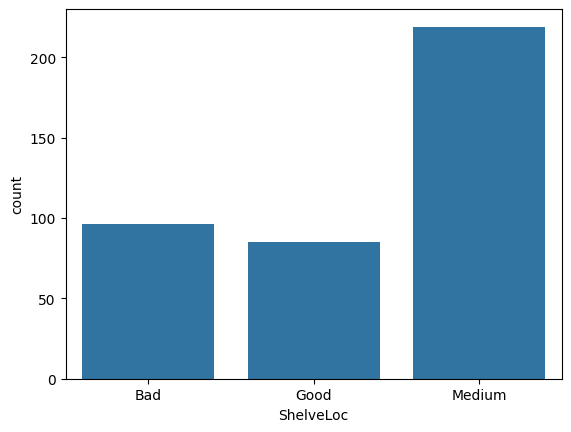

In [ ]:
#catgorical analysis
sns.countplot(x='ShelveLoc',data=df)

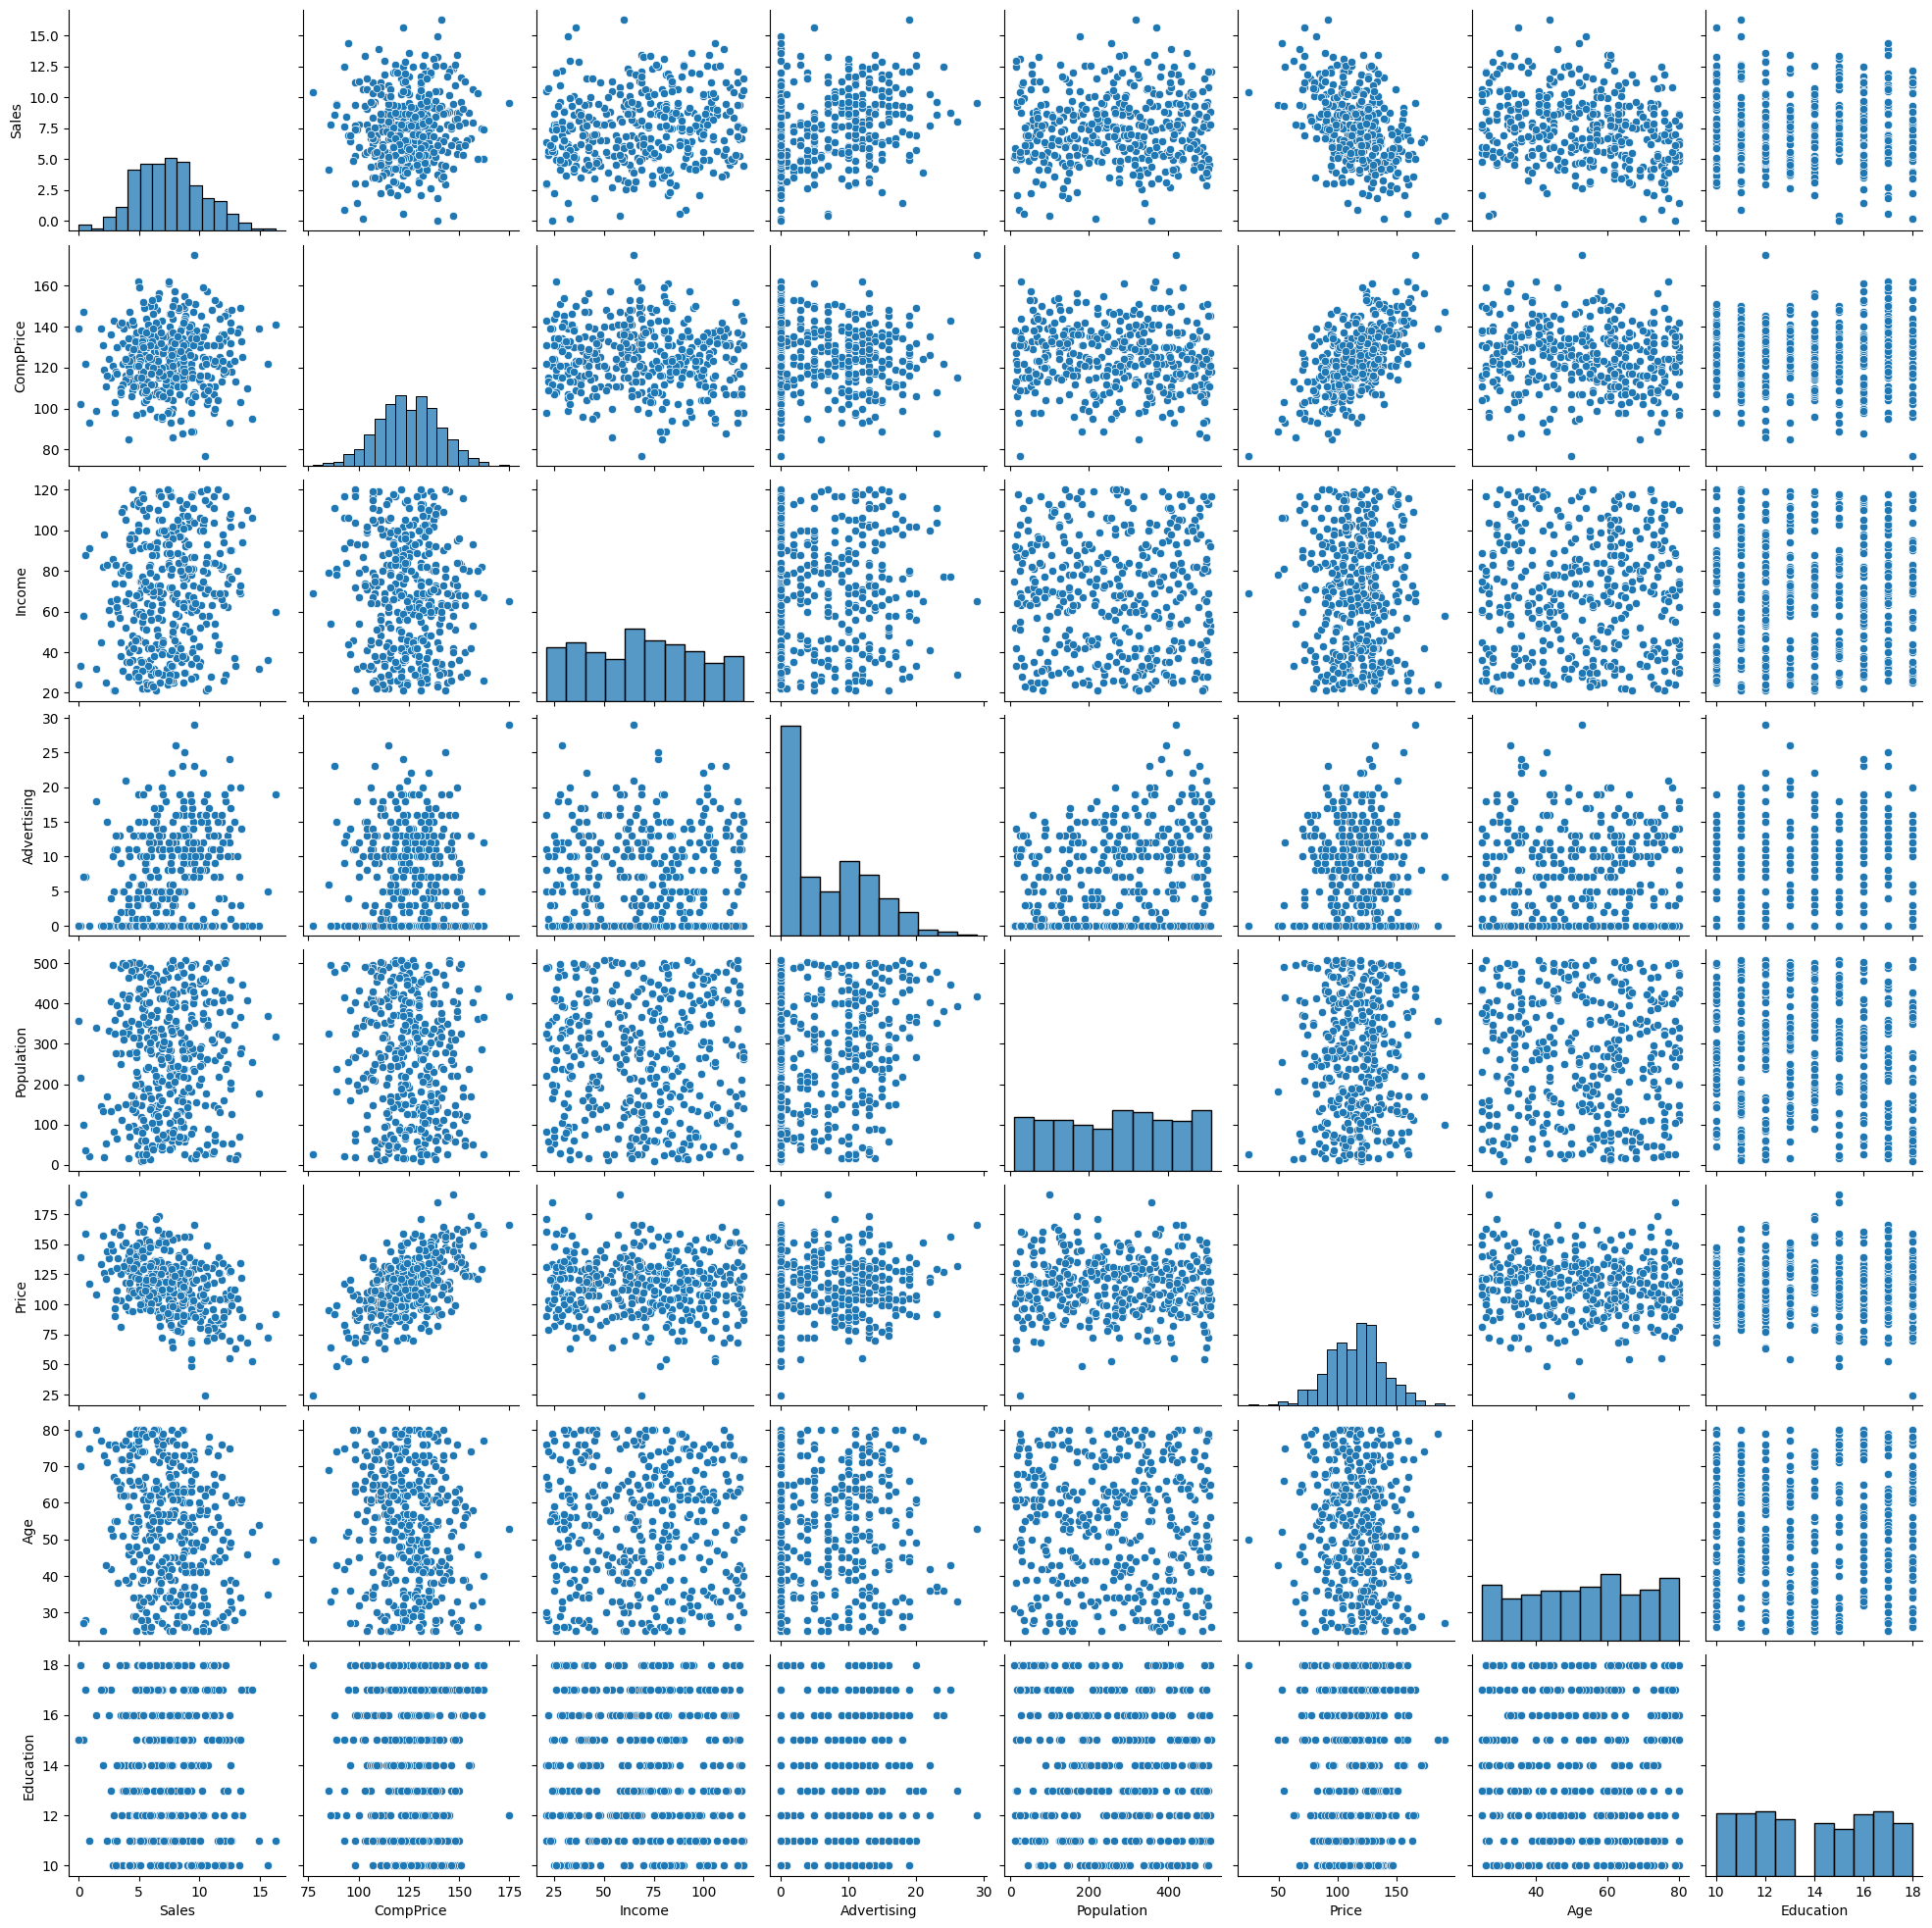

<Axes: >

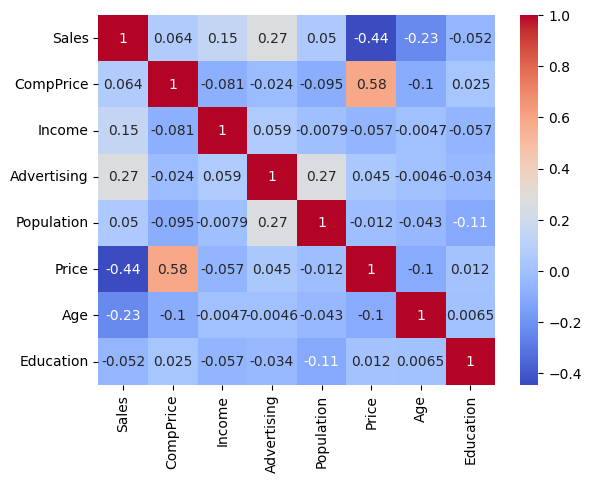

In [ ]:
#bivariate analysis
sns.pairplot(df)
plt.show()

sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap='coolwarm')

In [ ]:
#data preprocessing
df.isnull().sum()

,0
Sales,0
CompPrice,0
Income,0
Advertising,0
Population,0
Price,0
ShelveLoc,0
Age,0
Education,0
Urban,0


In [ ]:
#duplicate
df.drop_duplicates(inplace=True)

In [ ]:
#label encoding
le=LabelEncoder()

for col in df.select_dtypes(include='object'):
    df[col]=le.fit_transform(df[col])

In [ ]:
#train-test-split
# Create a new categorical target variable 'Sales_Category'
df['Sales_Category'] = df['Sales'].apply(lambda x: 'High' if x > df['Sales'].median() else 'Low')

X=df.drop(['Sales', 'Sales_Category'],axis=1)

y=df['Sales_Category']

X_train,X_test,y_train,y_test=train_test_split(
    X,y,
    test_size=0.2,
    random_state=42,
    stratify=y # Stratify can now be used as y is categorical
)

In [ ]:
#DT
dt=DecisionTreeClassifier(
    criterion='entropy',
    max_depth=5,
    random_state=42
)

dt.fit(X_train,y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=42)

In [ ]:
y_pred_dt=dt.predict(X_test)

In [ ]:
accuracy_score(y_test,y_pred_dt)

0.7125

In [ ]:
print(classification_report(y_test,y_pred_dt))

              precision    recall  f1-score   support

        High       0.69      0.78      0.73        40
         Low       0.74      0.65      0.69        40

    accuracy                           0.71        80
   macro avg       0.72      0.71      0.71        80
weighted avg       0.72      0.71      0.71        80



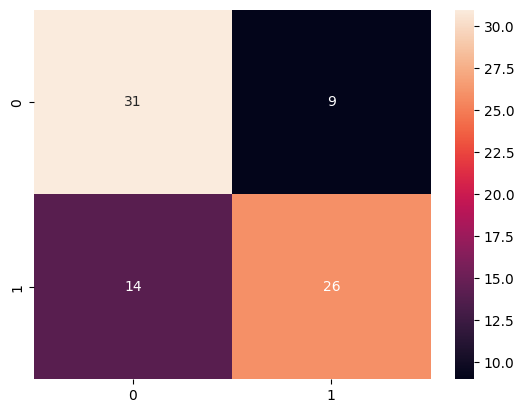

In [ ]:
sns.heatmap(confusion_matrix(y_test,y_pred_dt),
            annot=True,
            fmt='d')
plt.show()

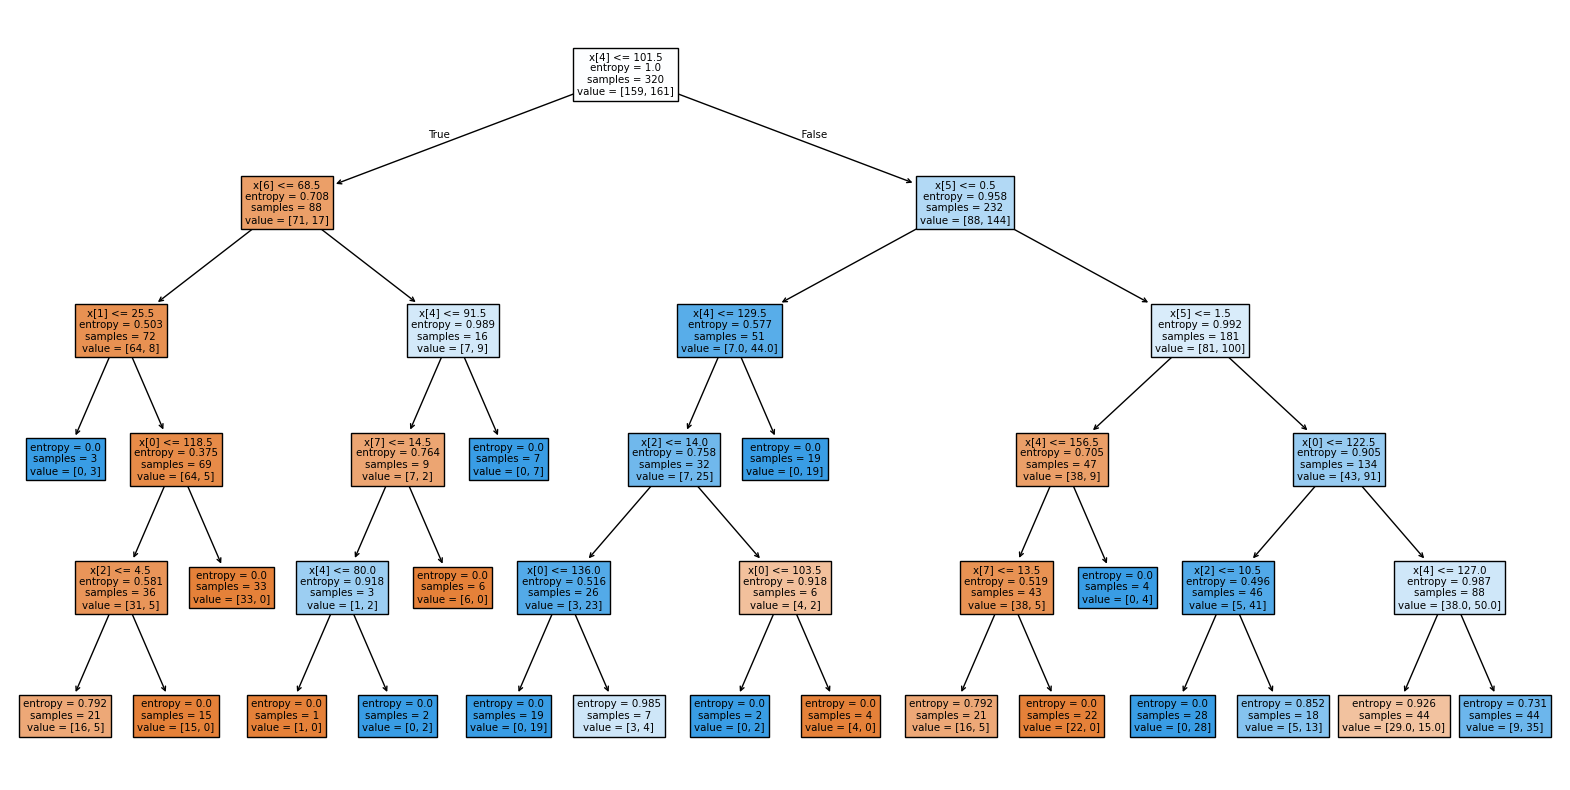

In [ ]:
plt.figure(figsize=(20,10))

tree.plot_tree(
    dt,
    filled=True
)

plt.show()

In [ ]:
#Random forest
rf=RandomForestClassifier(
    n_estimators=200,
    criterion='entropy',
    random_state=42
)

rf.fit(X_train,y_train)

RandomForestClassifier(criterion='entropy', n_estimators=200, random_state=42)

In [ ]:
y_pred_rf=rf.predict(X_test)

In [ ]:
accuracy_score(y_test,y_pred_rf)

0.775

In [ ]:
print(classification_report(y_test,y_pred_rf))

              precision    recall  f1-score   support

        High       0.79      0.75      0.77        40
         Low       0.76      0.80      0.78        40

    accuracy                           0.78        80
   macro avg       0.78      0.78      0.77        80
weighted avg       0.78      0.78      0.77        80



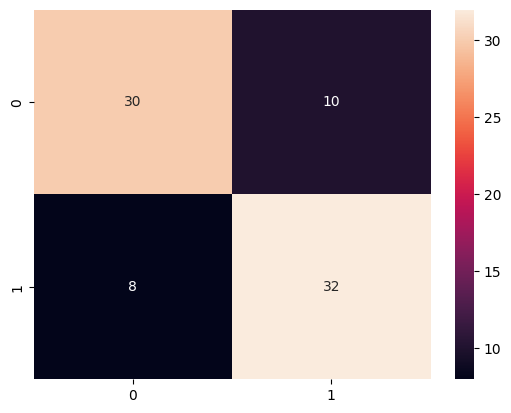

In [ ]:
sns.heatmap(confusion_matrix(y_test,y_pred_rf),
            annot=True,
            fmt='d')
plt.show()

In [ ]:
#cross validation
#DT
cv_dt=cross_val_score(
    dt,
    X,
    y,
    cv=5
)

cv_dt.mean()

np.float64(0.7000000000000001)

In [ ]:
#RF
cv_rf=cross_val_score(
    rf,
    X,
    y,
    cv=5
)

cv_rf.mean()

np.float64(0.8)

In [ ]:
#feature importance
importance=pd.DataFrame({
    'Feature':X.columns,
    'Importance':rf.feature_importances_
})

importance.sort_values(
    by='Importance',
    ascending=False,
    inplace=True
)

importance

,Feature,Importance
4,Price,0.259939
0,CompPrice,0.129820
6,Age,0.123006
1,Income,0.110242
2,Advertising,0.100847
5,ShelveLoc,0.091372
3,Population,0.087806
7,Education,0.064932
8,Urban,0.018410
9,US,0.013626


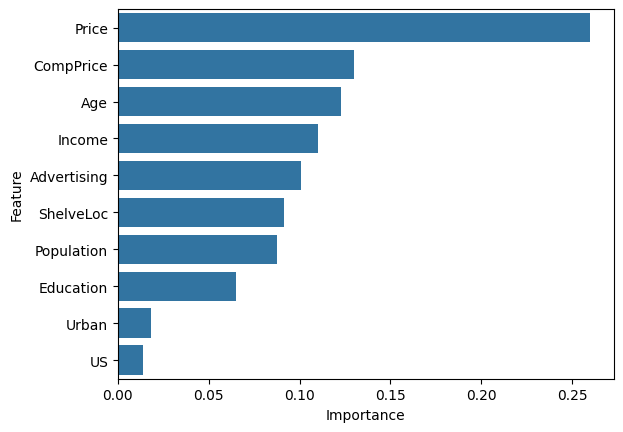

In [ ]:
#visualization
sns.barplot(
    x='Importance',
    y='Feature',
    data=importance
)
plt.show()

In [ ]:
#Assignment1
#converting sales into categorical data
df=pd.read_csv('/content/Company_Data.csv')

df['Sales_Category']=np.where(
    df['Sales']>df['Sales'].median(),
    'High',
    'Low'
)

df.drop('Sales',axis=1,inplace=True)

In [ ]:
y=df['Sales_Category']

In [ ]:
#Business Objective:
'''Identify factors responsible for high sales.'''

#Business Decisions
#First Moment
'''Average sales level.'''
#Second Moment
'''Market volatility.'''
#Third Moment
'''Identify unusual sales regions.'''
#Fourth Moment
'''Detect extreme sales behavior.'''

#Business Benefits
'''Better inventory planning
Improved marketing campaigns
Store performance improvement'''

In [ ]:
#Assignment2
df = pd.read_csv('/content/Diabetes.csv')
df.head()

,Number of times pregnant,Plasma glucose concentration,Diastolic blood pressure,Triceps skin fold thickness,2-Hour serum insulin,Body mass index,Diabetes pedigree function,Age (years),Class variable
0,6,148,72,35,0,33.6,0.627,50,YES
1,1,85,66,29,0,26.6,0.351,31,NO
2,8,183,64,0,0,23.3,0.672,32,YES
3,1,89,66,23,94,28.1,0.167,21,NO
4,0,137,40,35,168,43.1,2.288,33,YES


In [ ]:
#checking class distribution
df.columns = df.columns.str.strip() # Clean column names by stripping whitespace
df['Class variable'].value_counts()

,count
Class variable,
NO,500
YES,268


In [ ]:
#Missing val
cols = ['Plasma glucose concentration',
        'Diastolic blood pressure',
        'Triceps skin fold thickness',
        '2-Hour serum insulin',
        'Body mass index']

for col in cols:
    df[col] = df[col].replace(0,np.nan)
    df[col] = df[col].fillna(df[col].median())

In [ ]:
#define x and y
X = df.drop('Class variable',axis=1)
y = df['Class variable']

In [ ]:
# Train-test split for Diabetes dataset
X_train_dia, X_test_dia, y_train_dia, y_test_dia = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y # 'Class variable' is categorical, so stratify is appropriate
)

In [ ]:
#DT model
dt = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    random_state=42
)

dt.fit(X_train,y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [ ]:
#RF
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    random_state=42
)

rf.fit(X_train,y_train)

RandomForestClassifier(max_depth=6, n_estimators=300, random_state=42)

In [ ]:
#Assignment3
df = pd.read_csv('/content/Fraud_check.csv')
df.head()

,Undergrad,Marital.Status,Taxable.Income,City.Population,Work.Experience,Urban
0,NO,Single,68833,50047,10,YES
1,YES,Divorced,33700,134075,18,YES
2,NO,Married,36925,160205,30,YES
3,YES,Single,50190,193264,15,YES
4,NO,Married,81002,27533,28,NO


In [ ]:
#creating target variables
df['Risk'] = np.where(
    df['Taxable.Income'] <= 30000,
    'Risky',
    'Good'
)

In [ ]:
#drop original target
df.drop('Taxable.Income',
        axis=1,
        inplace=True)

In [ ]:
#encoding categoricals
le = LabelEncoder()

for col in df.select_dtypes(include='object'):
    df[col] = le.fit_transform(df[col])

In [ ]:
#defining x and y
X = df.drop('Risk',
            axis=1)

y = df['Risk']

In [ ]:
#DT
dt = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=5,
    random_state=42
)

dt.fit(X_train,y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=42)

In [ ]:
#RF
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

rf.fit(X_train,y_train)

RandomForestClassifier(n_estimators=300, random_state=42)

In [ ]:
#Assignment4
df = pd.read_csv('/content/HR_DT.csv')
df.head()

,Position of the employee,no of Years of Experience of employee,monthly income of employee
0,Business Analyst,1.1,39343
1,Junior Consultant,1.3,46205
2,Senior Consultant,1.5,37731
3,Manager,2.0,43525
4,Country Manager,2.2,39891


In [ ]:
#checking col names
df.columns

Index(['Position of the employee', 'no of Years of Experience of employee',
       ' monthly income of employee'],
      dtype='object')

In [ ]:
#creating salary categories
df['Salary_Category'] = pd.qcut(
    df[' monthly income of employee'],
    q=3,
    labels=['Low',
            'Medium',
            'High']
)

In [ ]:
#drop original salary
df.drop(' monthly income of employee',
        axis=1,
        inplace=True)

In [ ]:
#encode categoicals
le = LabelEncoder()

for col in df.select_dtypes(include='object'):
    df[col] = le.fit_transform(df[col])

In [ ]:
# defining x and y for HR_DT dataset
X = df.drop('Salary_Category', axis=1)
y = df['Salary_Category']

In [ ]:
# Train-test split for HR_DT dataset
X_train_hr, X_test_hr, y_train_hr, y_test_hr = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y # 'Salary_Category' is categorical, so stratify is appropriate
)

In [ ]:
#DT
dt = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=6,
    random_state=42
)

dt.fit(X_train,y_train)

#RF
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

rf.fit(X_train,y_train)

RandomForestClassifier(n_estimators=300, random_state=42)

In [ ]:
#Common evaltuation
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [ ]:
#DT evaluation
y_pred_dt = dt.predict(X_test)

print("Accuracy:",
      accuracy_score(y_test,y_pred_dt))

print(classification_report(
      y_test,y_pred_dt))

Accuracy: 0.725
              precision    recall  f1-score   support

        High       0.72      0.72      0.72        40
         Low       0.72      0.72      0.72        40

    accuracy                           0.72        80
   macro avg       0.72      0.72      0.72        80
weighted avg       0.72      0.72      0.72        80



In [ ]:
#RF evaluation
y_pred_rf = rf.predict(X_test)

print("Accuracy:",
      accuracy_score(y_test,y_pred_rf))

print(classification_report(
      y_test,y_pred_rf))

Accuracy: 0.775
              precision    recall  f1-score   support

        High       0.81      0.72      0.76        40
         Low       0.75      0.82      0.79        40

    accuracy                           0.78        80
   macro avg       0.78      0.77      0.77        80
weighted avg       0.78      0.78      0.77        80



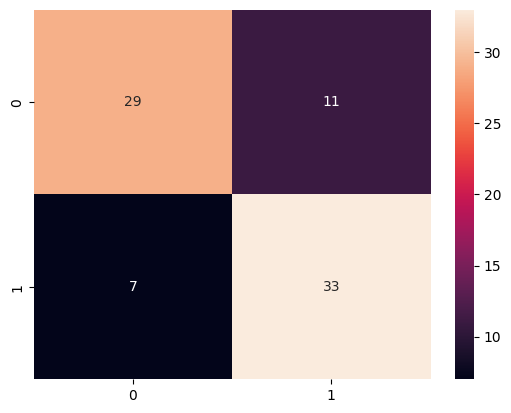

In [ ]:
#CM
sns.heatmap(
    confusion_matrix(
        y_test,
        y_pred_rf
    ),
    annot=True,
    fmt='d'
)

plt.show()

In [ ]:
#cross validation
from sklearn.model_selection import cross_val_score

cv_dt = cross_val_score(
    dt,
    X,
    y,
    cv=5
)

cv_rf = cross_val_score(
    rf,
    X,
    y,
    cv=5
)

print("DT CV Mean:",cv_dt.mean())
print("RF CV Mean:",cv_rf.mean())

DT CV Mean: 0.9335897435897437
RF CV Mean: 0.9133333333333333


                                 Feature  Importance
1  no of Years of Experience of employee    0.928668
0               Position of the employee    0.071332


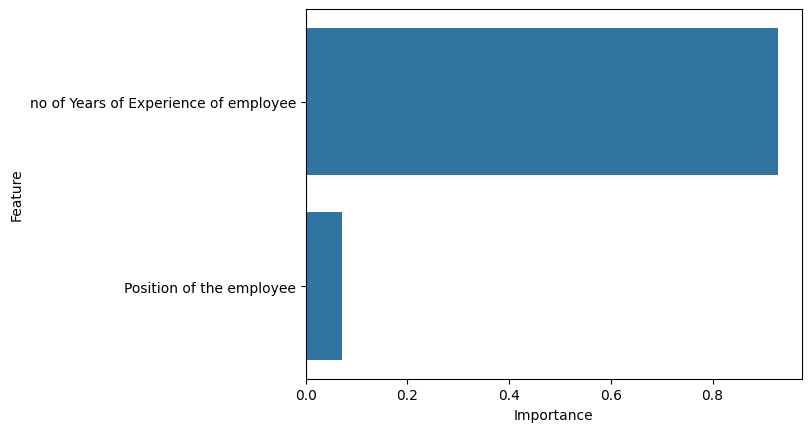

In [ ]:
#feature importance
# Train a new RandomForestClassifier for the HR_DT dataset
rf_hr = RandomForestClassifier(
    n_estimators=300, # Using similar parameters as previous RF models
    random_state=42
)
rf_hr.fit(X_train_hr, y_train_hr) # Train on the HR_DT training data

importance = pd.DataFrame({
    'Feature':X.columns,
    'Importance':rf_hr.feature_importances_ # Use importances from the newly trained model
}).sort_values(
    by='Importance',
    ascending=False
)

print(importance)

sns.barplot(
    x='Importance',
    y='Feature',
    data=importance
)

plt.show()